# ENG2440 Assignment 3: Molecular Property Prediction with Graph Neural Networks

Name: Md Aman Khan

Student ID: 25011138

Imports

In [1]:
from scripts.data import canonical_smiles, graph_is_valid, inspect_dataset, find_duplicates, clean_dataset
from scripts.splits import murcko_scaffold, random_split, scaffold_split, verify_split, split_summary
from scripts.fingerprints import morgan_fingerprints, train_baseline, select_baseline, tanimoto, nearest_training_molecule
from scripts.model import AtomEncoder, BondEncoder, GNN, count_parameters
from scripts.training import set_seed, train_model, predict, load_run, save_run
from scripts.evaluation import select_threshold, classification_metrics, summarize_runs, comparison_table
from scripts.plots import draw_molecules, draw_graph_view, plot_history, plot_roc_pr, plot_confusion_matrix, plot_similar_pair

from pathlib import Path
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Draw

import torch
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader

from torch_geometric.utils.smiles import x_map, e_map

RDLogger.DisableLog("rdApp.*")

/Users/md.khan/Documents/code/medical-imaging-assignment-3/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/md.khan/Documents/code/medical-imaging-assignment-3/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Configuration

In [2]:
DATA_ROOT = Path("data/MoleculeNet")
CHECKPOINT_DIR = Path("checkpoints")
SEED = 42
SEEDS = [42, 43, 44]

SPLIT_FRACTIONS = (0.70, 0.15, 0.15)

FINGERPRINT_RADIUS = 2
FINGERPRINT_BITS = 2048

DEVICE = torch.device("cpu") 

HIDDEN_CHANNELS = 64
NUM_LAYERS = 3
DROPOUT = 0.2

BATCH_SIZE = 32
EPOCHS = 100
LEARNING_RATE = 1e-3
PATIENCE = 20

Verify setup

In [3]:
dataset = MoleculeNet(root=str(DATA_ROOT), name="BBBP")

print(dataset)
print("Number of molecules:", len(dataset))
print("First graph:", dataset[0])

BBBP(2039)
Number of molecules: 2039
First graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])


### Part A. Define the task and inspect the dataset

State the input, output, unit of analysis and intended technical use. Explain what the positive and negative labels mean.

**Input**: One molecule, stored as a SMILES string and converted into a graph where atoms are the nodes and bonds are the edges. For a molecule with n atoms and m bonds, PyTorch Geometric gives x of shape [n, 9], nine categorical atom features per atom, edge_index of shape [2, 2m] because every bond is stored in both directions, and edge_attr of shape [2m, 3]. The integers in x and edge_attr are category codes and not measured amounts, so they must be one-hot encoded or embedded first. There is no 3D conformer, only the 2D connectivity with atom and bond types.

**Output**: One probability per molecule that the compound penetrates the blood-brain barrier. Message passing updates the atom vectors, pooling reduces them to a single vector for the whole molecule, and a binary head turns that into the probability. The prediction belongs to the molecule, not to any atom. A threshold chosen on validation turns it into a 0 or 1 decision.

**Unit of analysis**: The molecule. Splitting, training and evaluation are all per molecule, and no atom-level label exists. Two records with the same canonical SMILES are the same unit even when the original strings are written differently, which is why duplicates are dropped before either split is built.

**Intended technical use**: A coursework experiment comparing a Morgan-fingerprint baseline with a graph neural network on the same data, and measuring how much the estimate moves when the split changes from random to scaffold-based. At most it could prioritise compounds for a later experiment. It is not a clinical tool and has had no external validation.

**Positive class (1)**: the compound is recorded as penetrating the blood-brain barrier.

**Negative class (0)**: it is recorded as not penetrating.

Both are curated research labels, collected by Martins et al. (2012) from published permeability studies run under different assays, so they describe the compound rather than a patient and are not all equally reliable.

Load the full dataset and report its size, missing or non-finite labels, invalid or empty molecular graphs, class counts and class proportions.

In [4]:
table = inspect_dataset(dataset)
raw = pd.read_csv(DATA_ROOT / "bbbp" / "raw" / "BBBP.csv")

unparsable = [s for s in raw["smiles"] if Chem.MolFromSmiles(s) is None]

print("Rows in the raw BBBP.csv:", len(raw))
print("Molecules loaded by PyTorch Geometric:", len(dataset))
print("Dropped by the loader:", len(raw) - len(dataset))
print("Raw SMILES that RDKit cannot parse:", len(unparsable))
print()
print("In the loaded dataset:")
print("missing or non-finite labels:", int((~table["finite_label"]).sum()))
print("invalid SMILES:", int((~table["valid_smiles"]).sum()))
print("empty graphs with no atoms:", int((~table["has_atoms"]).sum()))
print()

counts = table["label"].value_counts().sort_index()
class_summary = pd.DataFrame({"count": counts, "proportion": (counts / len(table)).round(4)})
class_summary.index = ["0 (non-penetrating)", "1 (penetrating)"]

print(class_summary.to_string())

Rows in the raw BBBP.csv: 2050
Molecules loaded by PyTorch Geometric: 2039
Dropped by the loader: 11
Raw SMILES that RDKit cannot parse: 11

In the loaded dataset:
missing or non-finite labels: 0
invalid SMILES: 0
empty graphs with no atoms: 0

                     count  proportion
0 (non-penetrating)    479      0.2349
1 (penetrating)       1560      0.7651


Canonicalize every valid SMILES string using RDKit, then identify molecules that occur more than once, including molecules represented by different original SMILES strings. Report duplicate counts and check whether duplicate records have consistent labels.

In [5]:
print("SMILES canonicalized:", int(table["valid_smiles"].sum()), "of", len(table))
print("Unique canonical SMILES:", table["canonical_smiles"].nunique())
print()

consistent, conflicting = find_duplicates(table)

print("Canonical SMILES occurring more than once:", len(consistent) + len(conflicting))
print("with consistent labels:", len(consistent), "groups,", int(consistent["n_records"].sum()), "records")
print("with conflicting labels:", len(conflicting), "groups,", int(conflicting["n_records"].sum()), "records")
print()

example = conflicting.index[0]
print("One conflicting group, written two different ways in the source file:")
print(table[table["canonical_smiles"] == example][["smiles", "canonical_smiles", "label"]].to_string(index=False))

SMILES canonicalized: 2039 of 2039
Unique canonical SMILES: 1975

Canonical SMILES occurring more than once: 60
with consistent labels: 50 groups, 104 records
with conflicting labels: 10 groups, 20 records

One conflicting group, written two different ways in the source file:
                    smiles      canonical_smiles  label
     CC(=O)Oc1ccccc1C(O)=O CC(=O)Oc1ccccc1C(=O)O    0.0
C1=CC=CC(=C1C(O)=O)OC(C)=O CC(=O)Oc1ccccc1C(=O)O    1.0


The raw BBBP.csv has 2050 rows and the loader returns 2039. The 11 missing ones are SMILES that RDKit cannot parse and the loader skips, so the count comes from the raw file. The loaded dataset itself has no invalid SMILES, no empty graphs and no missing or non-finite labels.

1560 of the 2039 molecules are positive and 479 are negative, so 76.5% positive.

Canonicalization leaves 1975 unique molecules. 124 records fall into 60 canonical structures that occur more than once. 50 of the 60 groups agree on the label and 10 disagree. Aspirin is one of the 10, labelled 0 as CC(=O)Oc1ccccc1C(O)=O and 1 as C1=CC=CC(=C1C(O)=O)OC(C)=O.

Display at least six molecular structures, including examples from both classes. Include the SMILES string and label for every displayed molecule.

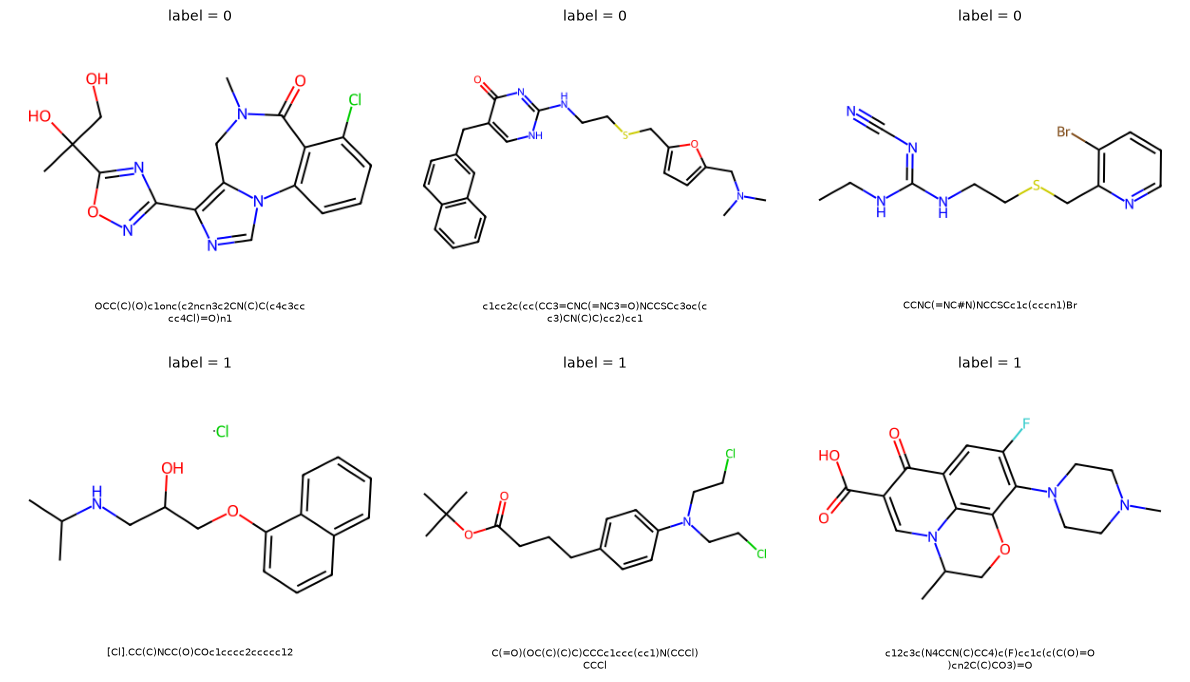

In [6]:
examples = pd.concat([
    table[table["label"] == 0].head(3),
    table[table["label"] == 1].head(3),
])

draw_molecules(examples["smiles"].tolist(), examples["label"].tolist())

Summarize the distributions of atom count and bond count. Inspect one graph and report `x.shape`, `edge_index.shape`, `edge_attr.shape`, `y` and `smiles`.

In [7]:
print(table[["n_atoms", "n_bonds"]].describe().round(2).to_string())

       n_atoms  n_bonds
count  2039.00  2039.00
mean     24.06    25.95
std      10.59    11.72
min       2.00     1.00
25%      18.00    19.00
50%      23.00    25.00
75%      28.50    31.00
max     132.00   145.00


In [8]:
graph = dataset[0]

print("x.shape:", tuple(graph.x.shape))
print("edge_index.shape:", tuple(graph.edge_index.shape))
print("edge_attr.shape:", tuple(graph.edge_attr.shape))
print("y:", graph.y)
print("smiles:", graph.smiles)

x.shape: (20, 9)
edge_index.shape: (2, 40)
edge_attr.shape: (40, 3)
y: tensor([[1.]])
smiles: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


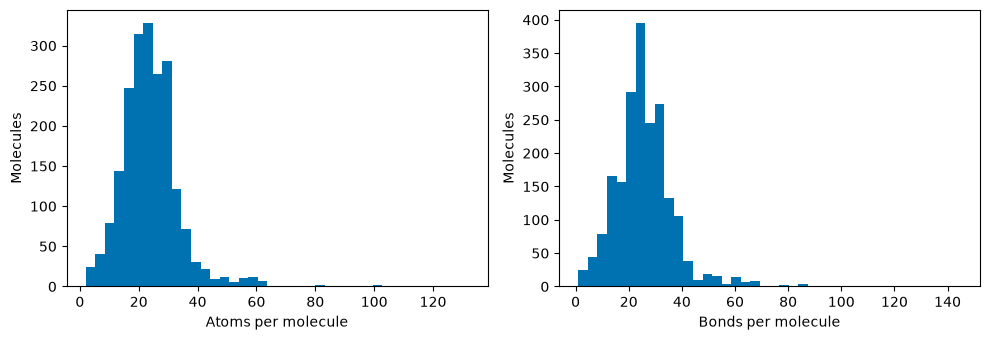

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, column, name in zip(axes, ["n_atoms", "n_bonds"], ["Atoms per molecule", "Bonds per molecule"]):
    ax.hist(table[column], bins=40, color="#0072B2")
    ax.set_xlabel(name)
    ax.set_ylabel("Molecules")

plt.tight_layout()
plt.show()

Required cleaning rule before splitting. Remove invalid SMILES or empty graphs and report their number. For records with the same canonical SMILES and consistent labels, retain one record. If the same canonical molecule has conflicting labels, remove all records in that conflicting group and report them. Perform both split strategies only after this cleaning step.

In [10]:
kept_index, cleaning_report = clean_dataset(table)

print(cleaning_report.to_string(index=False))
print()
print("Records before cleaning:", len(table))
print("Molecules kept:", len(kept_index))
print()
print("Conflicting groups removed:")
print(conflicting.to_string())

clean_table = table.loc[kept_index]
clean_graphs = dataset[torch.as_tensor(kept_index)]

                                 step  records_removed
       invalid SMILES or empty graphs                0
  records in label-conflicting groups               20
extra copies of consistent duplicates               54

Records before cleaning: 2039
Molecules kept: 1965

Conflicting groups removed:
                                                                                        n_records  n_distinct_labels
canonical_smiles                                                                                                    
CC(=O)Oc1ccccc1C(=O)O                                                                           2                  2
CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1                                                    2                  2
CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1                                      2                  2
CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2                                                              2                 

/var/folders/1j/5lph888j6sv_b6pj8q451qzc0000gq/T/ipykernel_99704/3904375332.py:12: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  clean_graphs = dataset[torch.as_tensor(kept_index)]


_Cleaning summary:_ Cleaning removes 74 of the 2039 records and leaves 1965 molecules. Nothing is dropped for an invalid SMILES or an empty graph, because the loader already discarded the 11 unparsable rows. 20 records go as 10 canonical structures whose copies carry opposite labels, listed above. Another 54 are extra copies of the 50 canonical structures whose copies agree, keeping one record of each. Both splits in Part C are built from these 1965 molecules.

### Part B. Construct and batch molecular graphs

Explain how atoms, bonds, node features and edge features are represented in the PyTorch Geometric graph. Identify the meaning of each categorical feature column. Encode every categorical atom and bond feature using either one-hot encoding or a trainable embedding. Clearly state which method you used. Raw integer category codes must not be treated as continuous numerical values.

In [11]:
atom_sizes = [len(values) for values in x_map.values()]
bond_sizes = [len(values) for values in e_map.values()]

print("Atom features, x[:, i]:")
for i, (name, values) in enumerate(x_map.items()):
    print(f"  [{i}] {name:<22} {len(values):>3} categories")

print()
print("Bond features, edge_attr[:, i]:")
for i, (name, values) in enumerate(e_map.items()):
    print(f"  [{i}] {name:<22} {len(values):>3} categories")

Atom features, x[:, i]:
  [0] atomic_num             119 categories
  [1] chirality                9 categories
  [2] degree                  11 categories
  [3] formal_charge           12 categories
  [4] num_hs                   9 categories
  [5] num_radical_electrons    5 categories
  [6] hybridization            8 categories
  [7] is_aromatic              2 categories
  [8] is_in_ring               2 categories

Bond features, edge_attr[:, i]:
  [0] bond_type               22 categories
  [1] stereo                   6 categories
  [2] is_conjugated            2 categories


In [12]:
torch.manual_seed(SEED)
atom_encoder = AtomEncoder(atom_sizes, HIDDEN_CHANNELS)
bond_encoder = BondEncoder(bond_sizes, HIDDEN_CHANNELS)

graph = clean_graphs[0]
print()
print("x:         ", tuple(graph.x.shape), "->", tuple(atom_encoder(graph.x).shape))
print("edge_attr: ", tuple(graph.edge_attr.shape), "->", tuple(bond_encoder(graph.edge_attr).shape))


x:          (20, 9) -> (20, 64)
edge_attr:  (40, 3) -> (40, 64)


_Node-feature columns:_ each atom is one row of x with nine columns: atomic_num, chirality, degree, formal_charge, num_hs, num_radical_electrons, hybridization, is_aromatic and is_in_ring. Every entry is a position in the matching list in PyTorch Geometric's x_map, so a 6 in the atomic_num column means the seventh entry of that list, not the quantity six.

_Edge-feature columns:_ each directed edge is one row of edge_attr with three columns: bond_type, stereo and is_conjugated, indexed into e_map the same way. A bond appears as two rows, one per direction.

_Encoding used:_ trainable embeddings. Each column gets its own nn.Embedding table sized to that column's number of categories; the nine atom embeddings are summed into one vector per atom and the three bond embeddings into one vector per edge. No arithmetic is done on the raw codes, so no ordering is implied between categories that have none, such as the hybridization states.

Display the same example molecule as a conventional chemical structure and as a node-edge graph. Explain how atoms and bonds correspond between the two views.

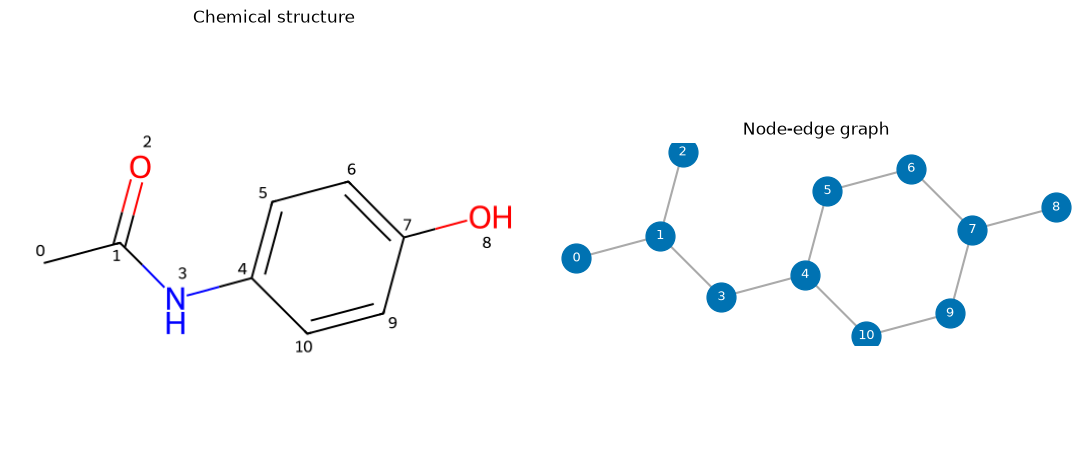

In [13]:
example_position = clean_table.index.get_loc(97)
example_graph = clean_graphs[example_position]

draw_graph_view(example_graph)

The molecule is paracetamol, CC(=O)Nc1ccc(O)cc1, record 97. Both panels show the same 11 atoms under the same numbering and the same coordinates.

Every atom is one node: node 0 is the methyl carbon, node 2 the carbonyl oxygen, node 3 the amide nitrogen, node 8 the hydroxyl oxygen, and nodes 4, 5, 6, 7, 9, 10 the aromatic ring. Hydrogens have no nodes, because RDKit keeps them implicit and stores the count in num_hs, which is why the H on the nitrogen on the left has no counterpart on the right.

Every bond is one edge. The ring appears as the cycle 4-5-6-7-9-10 in both views, and the substituents N3 to C4 and O8 to C7 hang off it in the same places. Bond type is not visible in the graph view: the C1=O2 double bond and the aromatic ring bonds are drawn as plain lines, because that information sits in edge_attr. Each bond is stored twice in edge_index, so 11 bonds give 22 columns while the picture draws 11 lines.

Create a PyTorch Geometric `DataLoader`. Print and explain the shapes of one batch, including `x`, `edge_index`, `edge_attr`, `batch` and `y`.

In [14]:
loader = DataLoader(clean_graphs, batch_size=BATCH_SIZE, shuffle=False)
example_batch = next(iter(loader))

print(example_batch)
print()
print("x:", tuple(example_batch.x.shape))
print("edge_index:", tuple(example_batch.edge_index.shape))
print("edge_attr:", tuple(example_batch.edge_attr.shape))
print("batch:", tuple(example_batch.batch.shape))
print("y:", tuple(example_batch.y.shape))

DataBatch(x=[770, 9], edge_index=[2, 1646], edge_attr=[1646, 3], smiles=[32], y=[32, 1], batch=[770], ptr=[33])

x: (770, 9)
edge_index: (2, 1646)
edge_attr: (1646, 3)
batch: (770,)
y: (32, 1)


A batch of 32 molecules is not padded into a fixed-size tensor. PyTorch Geometric concatenates the graphs into one large disconnected graph and renumbers the nodes, so every shape below counts atoms or edges rather than molecules, except y.

x is [770, 9]: the 32 molecules contribute 770 atoms in total, each still described by the same nine categorical columns. The 770 varies from batch to batch because molecules differ in size.

edge_index is [2, 1646]: 823 bonds across the batch, each stored in both directions. Node ids run from 0 to 769 over the whole batch, not from 0 within each molecule, which is what keeps the molecules separate. No edge ever joins two different molecules, so message passing cannot leak between them.

edge_attr is [1646, 3]: one row of three bond-feature codes per directed edge, matching edge_index column for column.

batch is [770]: for each atom, the index of the molecule it came from. It starts 0 repeated 20 times, then 1 repeated 23 times, matching the atom counts of the first molecules. This is the vector that graph-level pooling uses to collect each molecule's atoms back together.

y is [32, 1]: one label per molecule, so this is the only tensor whose first dimension is the number of graphs rather than the number of atoms or edges. It is the shape the model's output has to match.

Implement checks that labels are finite, every retained graph contains at least one atom, batch labels match the number of graphs, and no molecule is lost during batching.

In [15]:
assert all(graph_is_valid(graph) for graph in clean_graphs)
print("Labels finite and at least one atom per graph:", len(clean_graphs), "graphs")

batched_graphs = 0
for batch in loader:
    assert batch.y.shape[0] == batch.num_graphs
    assert int(batch.batch.max()) + 1 == batch.num_graphs
    batched_graphs += batch.num_graphs

print("Batch labels match the number of graphs in all", len(loader), "batches")
print("Molecules recovered from the loader:", batched_graphs, "of", len(clean_graphs))

assert batched_graphs == len(clean_graphs)
print("All checks passed")

Labels finite and at least one atom per graph: 1965 graphs
Batch labels match the number of graphs in all 62 batches
Molecules recovered from the loader: 1965 of 1965
All checks passed


### Part C. Create random and scaffold-based splits

Create two separate 70:15:15 train-validation-test evaluations using one fixed seed: (i) a stratified random split and (ii) a Bemis-Murcko scaffold split. Keep all molecules with the same scaffold in one subset and document how invalid or acyclic molecules are handled.

In [16]:
scaffolds = [murcko_scaffold(smiles) for smiles in clean_table["smiles"]]

print("Molecules:", len(scaffolds))
print("Unique scaffolds:", len(set(scaffolds)))
print("Acyclic molecules (empty scaffold):", scaffolds.count(""))
print("Molecules whose scaffold could not be computed:", sum(1 for s in scaffolds if s is None))

Molecules: 1965
Unique scaffolds: 1020
Acyclic molecules (empty scaffold): 95
Molecules whose scaffold could not be computed: 0


In [17]:
labels = clean_table["label"].to_numpy()

random_indices = random_split(labels, SPLIT_FRACTIONS, SEED)
scaffold_indices = scaffold_split(clean_table["smiles"].tolist(), SPLIT_FRACTIONS, SEED)

for name, (train, validation, test) in [("random", random_indices), ("scaffold", scaffold_indices)]:
    print(f"{name:<9} train {len(train):>4} | validation {len(validation):>3} | test {len(test):>3} | total {len(train) + len(validation) + len(test)}")

random    train 1375 | validation 295 | test 295 | total 1965
scaffold  train 1375 | validation 294 | test 296 | total 1965


_Handling of invalid or acyclic molecules:_ no molecule here is invalid. The 11 unparsable SMILES were dropped by the loader before Part A, and all 1965 cleaned molecules return a scaffold, so the None case never fires.

95 molecules are acyclic. Bemis-Murcko defines the scaffold as the ring systems plus the linkers joining them, so a molecule with no ring has an empty scaffold and RDKit returns the empty string. All 95 share that empty string, which makes them one group under the rule that molecules with the same scaffold stay together, and they all land in training. Splitting them across subsets would have broken the guarantee the scaffold split exists to provide.

Both splits are 70:15:15 on the same 1965 molecules with seed 42. The random split is stratified on the label, so each subset keeps the overall positive rate. The scaffold split cannot be stratified: whole scaffold groups are assigned, so subset sizes land near the targets rather than exactly on them, which is why validation and test are 294 and 296 rather than 295 each. Groups are sorted largest first and filled into train, then validation, then test, with the seed shuffling the order of equal-sized groups before that sort.

For both strategies, verify complete coverage, pairwise-disjoint indices and no overlap of canonical SMILES across the train, validation and test subsets.

In [18]:
checks = pd.DataFrame({
    "random": verify_split(random_indices, len(clean_table), clean_table["canonical_smiles"].tolist()),
    "scaffold": verify_split(scaffold_indices, len(clean_table), clean_table["canonical_smiles"].tolist()),
})

print(checks.to_string())

                                         random  scaffold
molecules assigned                         1965      1965
distinct molecules covered                 1965      1965
indices shared between subsets                0         0
canonical SMILES shared between subsets       0         0


Report molecule counts and positive-class proportions for every subset. For the scaffold split, also report unique-scaffold counts and verify that train, validation and test scaffolds are disjoint.

In [19]:
print("Random split")
print(split_summary(random_indices, labels).to_string())

print("\n\nScaffold split")
print(split_summary(scaffold_indices, labels, scaffolds).to_string())

print("\n\nWhole cleaned set positive proportion:", round(float(labels.mean()), 4))

Random split
            molecules  positive  negative  positive_proportion
train          1375.0    1050.0     325.0               0.7636
validation      295.0     225.0      70.0               0.7627
test            295.0     225.0      70.0               0.7627


Scaffold split
            molecules  positive  negative  positive_proportion  unique_scaffolds
train          1375.0    1053.0     322.0               0.7658             430.0
validation      294.0     230.0      64.0               0.7823             294.0
test            296.0     217.0      79.0               0.7331             296.0


Whole cleaned set positive proportion: 0.7634


In [20]:
print(verify_split(scaffold_indices, len(clean_table), clean_table["canonical_smiles"].tolist(), scaffolds).to_string())

molecules assigned                         1965
distinct molecules covered                 1965
indices shared between subsets                0
canonical SMILES shared between subsets       0
scaffolds shared between subsets              0


Keep each test set untouched until final evaluation. Explain why a random split can place close chemical analogues in training and test data and thereby produce an optimistic estimate of generalization.

Neither test set is read until Part F. The fingerprint hyperparameters and decision threshold in Part D, and the architecture, training budget and early-stopping point in Part E, are all chosen on the validation subset of the matching split. Each test set is scored once, with everything already frozen.

A random split assigns molecules independently of structure, and BBBP is not a collection of independent molecules. Its 1965 cleaned molecules carry only 1020 distinct Bemis-Murcko scaffolds, so most of the data arrives in families of close analogues that share a core and differ in a substituent. Random assignment cuts straight through those families and leaves one member in training while another lands in test.

A model can then score well on test by recognising a core it has already memorised, rather than by generalising to chemistry it has not seen. Whether a particular substituent switches blood-brain barrier penetration off is the hard part of the task, and a test set full of near-copies of training molecules barely asks the question. The resulting estimate is optimistic for the use that matters, which is predicting for a new chemical series.

The scaffold split removes that shortcut by construction, since every molecule sharing a scaffold is placed in the same subset. The C.3 table shows the cost: train holds 430 scaffolds across 1375 molecules while validation and test hold one scaffold per molecule, and the positive rate drifts from 0.783 in validation to 0.733 in test because whole groups move together and the label balance cannot be controlled. A lower score under this split is the honest number, not a worse model.

### Part D. Build a non-neural fingerprint baseline

Generate Morgan/ECFP fingerprints with RDKit. State the radius and fingerprint length and explain what the fingerprint represents.

In [21]:
fingerprints = morgan_fingerprints(clean_table["smiles"].tolist(), FINGERPRINT_RADIUS, FINGERPRINT_BITS)

print("Radius:", FINGERPRINT_RADIUS)
print("Length:", FINGERPRINT_BITS)
print("Fingerprint matrix:", fingerprints.shape, fingerprints.dtype)

Radius: 2
Length: 2048
Fingerprint matrix: (1965, 2048) uint8


Morgan fingerprints are generated with radius 2 and length 2048, the ECFP4 setting. Every molecule becomes one row of 2048 zeros and ones.

The fingerprint records which local substructures the molecule contains. RDKit walks outward from each atom, collects the circular neighbourhood reachable in up to 2 bonds, and hashes each distinct neighbourhood to one of the 2048 positions. A bit is 1 if the molecule contains at least one fragment hashing there. It is a presence-or-absence list of fragments, so it does not record how many times a fragment occurs, how fragments are arranged, or the molecule's global shape.

Train a logistic-regression classifier using training data only. If class weighting or another imbalance method is used, estimate it from the training subset only and justify it.

In [22]:
splits = {"random": random_indices, "scaffold": scaffold_indices}

baselines = {}
for name, (train, validation, test) in splits.items():
    n_positive = int(labels[train].sum())
    n_negative = len(train) - n_positive

    baselines[name] = train_baseline(fingerprints[train], labels[train], class_weight="balanced", seed=SEED)

    print(f"{name:<9} trained on {len(train)} molecules "
          f"({n_negative} negative, {n_positive} positive) | "
          f"balanced weights  0: {len(train) / (2 * n_negative):.3f}  1: {len(train) / (2 * n_positive):.3f}")

random    trained on 1375 molecules (325 negative, 1050 positive) | balanced weights  0: 2.115  1: 0.655
scaffold  trained on 1375 molecules (322 negative, 1053 positive) | balanced weights  0: 2.135  1: 0.653


Two classifiers are fitted, one per split, each on the 1375 training molecules of that split. Validation and test fingerprints are never passed to fit.

The training data is roughly 76% positive, so class weighting is a candidate: without it the model can lower total error by leaning towards the positive class and suppressing the 325 negatives. class_weight="balanced" weights each class by n_train / (2 × n_class) using the training counts printed above, so nothing from validation or test enters the weights. Whether to apply it is chosen on validation in D.3.

Use validation data to select hyperparameters and one decision threshold. Freeze both before evaluating the corresponding test set once.

In [23]:
BASELINE_GRID = [(c, weight) for c in (0.01, 0.1, 1.0, 10.0) for weight in (None, "balanced")]

baseline_settings = {}
for name, (train, validation, test) in splits.items():
    model, settings, search = select_baseline(
        fingerprints[train], labels[train],
        fingerprints[validation], labels[validation],
        BASELINE_GRID, seed=SEED,
    )
    baselines[name] = model
    baseline_settings[name] = settings

    print(f"=== {name} ===")
    print(search.to_string(index=False))
    print("selected:", settings)
    print()

=== random ===
    C class_weight  val_roc_auc
 0.01         None       0.8971
 0.01     balanced       0.9059
 0.10         None       0.9092
 0.10     balanced       0.9076
 1.00         None       0.8974
 1.00     balanced       0.8973
10.00         None       0.8874
10.00     balanced       0.8863
selected: {'C': 0.1, 'class_weight': None, 'val_roc_auc': 0.9092, 'threshold': 0.6802}

=== scaffold ===
    C class_weight  val_roc_auc
 0.01         None       0.8454
 0.01     balanced       0.8425
 0.10         None       0.8613
 0.10     balanced       0.8606
 1.00         None       0.8605
 1.00     balanced       0.8594
10.00         None       0.8463
10.00     balanced       0.8447
selected: {'C': 0.1, 'class_weight': None, 'val_roc_auc': 0.8613, 'threshold': 0.7841}



Eight combinations are fitted per split, crossing C over 0.01, 0.1, 1 and 10 with class_weight over None and "balanced". Each is trained on the training subset and scored by ROC-AUC on validation, which is threshold-free. C = 0.1 with no class weighting wins on both splits.

The threshold is then chosen from that model's validation probabilities by maximising balanced accuracy, giving 0.6802 for the random split and 0.7841 for the scaffold split. Balanced accuracy weights sensitivity and specificity equally, which matters because Part F reports both. Both the hyperparameters and the threshold are now frozen, and neither test set has been touched.

Report the random seed and all settings needed to reproduce the baseline for both split strategies.

In [24]:
reproducibility = pd.DataFrame({
    name: {
        "seed": SEED,
        "molecules after cleaning": len(clean_table),
        "split fractions": str(SPLIT_FRACTIONS),
        "train/validation/test": "/".join(str(len(i)) for i in splits[name]),
        "fingerprint": f"Morgan radius {FINGERPRINT_RADIUS}, {FINGERPRINT_BITS} bits",
        "grid searched": "C in 0.01/0.1/1/10 x class_weight in None/balanced",
        "selection metric": "validation ROC-AUC",
        "selected C": settings["C"],
        "selected class_weight": str(settings["class_weight"]),
        "solver": baselines[name].get_params()["solver"],
        "max_iter": baselines[name].get_params()["max_iter"],
        "threshold rule": "max balanced accuracy on validation",
        "threshold": settings["threshold"],
    }
    for name, settings in baseline_settings.items()
})

print(reproducibility.to_string())

                                                                      random                                            scaffold
seed                                                                      42                                                  42
molecules after cleaning                                                1965                                                1965
split fractions                                            (0.7, 0.15, 0.15)                                   (0.7, 0.15, 0.15)
train/validation/test                                           1375/295/295                                        1375/294/296
fingerprint                                       Morgan radius 2, 2048 bits                          Morgan radius 2, 2048 bits
grid searched             C in 0.01/0.1/1/10 x class_weight in None/balanced  C in 0.01/0.1/1/10 x class_weight in None/balanced
selection metric                                          validation ROC-AUC                     

### Part E. Implement and train a graph neural network

Implement a small bond-aware message-passing model in PyTorch Geometric. Use at least two message-passing layers, a graph-level pooling operation and a binary-classification head. Bond features must participate in message passing. Report the architecture, node-feature encoding, edge-feature encoding and parameter count.

In [25]:
torch.manual_seed(SEED)
model = GNN(atom_sizes, bond_sizes, hidden_channels=HIDDEN_CHANNELS, num_layers=NUM_LAYERS, dropout=DROPOUT)

print(model)

GNN(
  (atom_encoder): AtomEncoder(
    (embeddings): ModuleList(
      (0): Embedding(119, 64)
      (1): Embedding(9, 64)
      (2): Embedding(11, 64)
      (3): Embedding(12, 64)
      (4): Embedding(9, 64)
      (5): Embedding(5, 64)
      (6): Embedding(8, 64)
      (7-8): 2 x Embedding(2, 64)
    )
  )
  (bond_encoders): ModuleList(
    (0-2): 3 x BondEncoder(
      (embeddings): ModuleList(
        (0): Embedding(22, 64)
        (1): Embedding(6, 64)
        (2): Embedding(2, 64)
      )
    )
  )
  (convs): ModuleList(
    (0-2): 3 x GINEConv(nn=Sequential(
      (0): Linear(in_features=64, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=64, bias=True)
    ))
  )
  (norms): ModuleList(
    (0-2): 3 x BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (head): Linear(in_features=64, out_features=1, bias=True)
)


In [26]:
print("Trainable parameters:", count_parameters(model))

model.eval()
with torch.no_grad():
    logits = model(example_batch)

print("batch of", example_batch.num_graphs, "graphs ->", tuple(logits.shape))

Trainable parameters: 67268
batch of 32 graphs -> (32,)


Architecture: atom encoder, then three GINEConv message-passing layers, then mean pooling over each molecule's atoms, then a linear head to one logit. Each GINEConv wraps a two-layer MLP of 64 to 128 to 64 units, and is followed by batch normalisation, ReLU and dropout at 0.2. The model has 67,268 trainable parameters.

Node-feature encoding: the nine categorical atom columns each get their own embedding table sized to that column's number of categories, and the nine 64-dimensional vectors are summed into one vector per atom.

Edge-feature encoding: the three categorical bond columns are embedded the same way into one 64-dimensional vector per directed edge. Each of the three layers has its own bond embedding tables, so a bond can mean something different at different depths.

Bond features in message passing: GINEConv adds the edge embedding to the neighbour's node vector before the MLP is applied, so every message a node receives depends on the bond it arrived along. Setting all bond features to zero changes the model's output, which confirms they are used rather than ignored.

The output is one logit per molecule, shape [32] for a batch of 32, matching y after view(-1).

State and justify the loss, optimizer, learning rate, batch size, epoch budget, class-imbalance handling and early-stopping or checkpoint rule. Base model selection only on validation data.

In [27]:
CHECKPOINT_DIR.mkdir(exist_ok=True)

POS_WEIGHT = None
GNN_CONFIG = (HIDDEN_CHANNELS, NUM_LAYERS, DROPOUT, LEARNING_RATE, BATCH_SIZE, EPOCHS, PATIENCE, POS_WEIGHT)

gnn_runs = {}
for name, (train, validation, test) in splits.items():
    train_loader = DataLoader(clean_graphs[train], batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(clean_graphs[validation], batch_size=BATCH_SIZE, shuffle=False)

    set_seed(SEED)
    model = GNN(atom_sizes, bond_sizes, HIDDEN_CHANNELS, NUM_LAYERS, DROPOUT)

    path = CHECKPOINT_DIR / f"gnn_{name}_seed{SEED}.pt"
    saved = load_run(path, GNN_CONFIG)
    if saved is None:
        model, history = train_model(
            model, train_loader, val_loader, DEVICE,
            epochs=EPOCHS, lr=LEARNING_RATE, pos_weight=POS_WEIGHT, patience=PATIENCE,
        )
        save_run(path, model, history, GNN_CONFIG)
    else:
        model.load_state_dict(saved[0])
        history = saved[1]

    gnn_runs[(name, SEED)] = {"model": model, "history": history}

    best = history["val_roc_auc"].idxmax()
    print(f"{name:<9} epochs run {len(history):>3} | best val ROC-AUC {history.loc[best, 'val_roc_auc']:.4f} "
          f"at epoch {int(history.loc[best, 'epoch'])}")

random    epochs run  34 | best val ROC-AUC 0.9097 at epoch 14
scaffold  epochs run  72 | best val ROC-AUC 0.8764 at epoch 52


Loss: binary cross-entropy on the logits (BCEWithLogitsLoss). The task is one binary label per molecule and the model emits one logit, so this is the matching loss; taking it from logits rather than from a sigmoid output is the numerically stable form.

Optimizer and learning rate: Adam at 1e-3, the standard default for a network of this size. No schedule is used, since early stopping already ends training once validation stops improving.

Batch size: 32, the same as Part B, giving about 43 training batches per epoch. Training batches are shuffled, validation batches are not.

Epoch budget: at most 100 epochs. Neither run reaches it; the random split stops after 34 and the scaffold split after 72.

Class-imbalance handling: the loss is not reweighted. Imbalance is handled by the decision threshold chosen on validation, the same rule the baseline uses, so both models are treated identically in Part F. Part D's validation search preferred no class weighting, and reweighting the loss as well as moving the threshold would correct for the same imbalance twice.

Early stopping and checkpointing: after every epoch the model is scored on the validation subset by ROC-AUC. The weights from the best epoch are kept in memory and restored when training ends, and training stops once 20 epochs pass with no improvement. The best epoch was 14 for the random split and 52 for the scaffold split, both well before their runs ended, so the restored weights are not simply the final ones. Selection uses validation only; no test subset is read in this loop.

Plot training and validation loss and the principal validation metric. Identify underfitting, instability or overfitting without consulting test results.

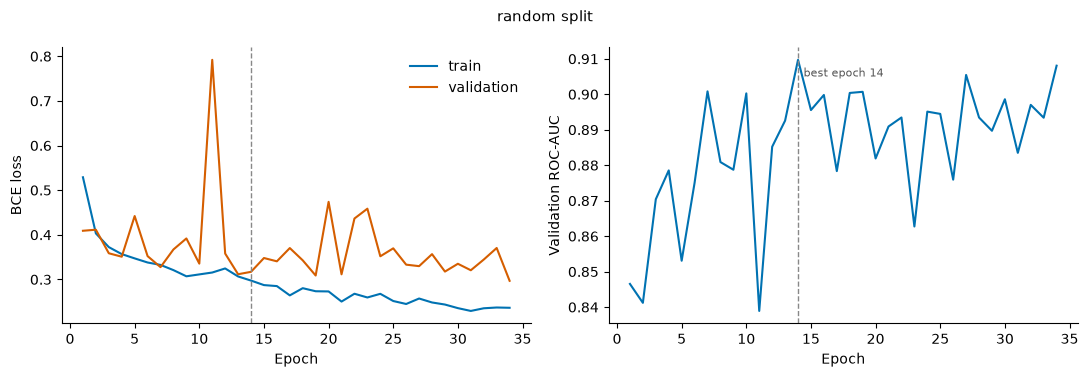

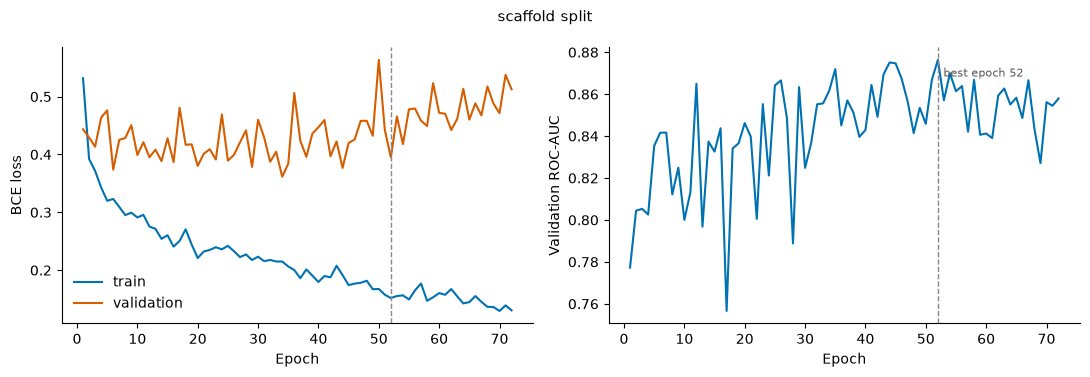

In [28]:
for name in splits:
    plot_history(gnn_runs[(name, SEED)]["history"], title=f"{name} split")

Random split. Training and validation loss fall together and stay close, ending at 0.237 and 0.297, so there is no overfitting within the 34 epochs run. Validation ROC-AUC rises to about 0.90 by epoch 10 then oscillates between roughly 0.86 and 0.91 without trending up, so the model is not underfitting either: it has stopped learning rather than failed to learn. It is unstable epoch to epoch, with validation loss spiking to 0.80 at epoch 11 and a standard deviation of 0.011 in validation ROC-AUC over the last 15 epochs.

Scaffold split. This one overfits. Training loss falls steadily from 0.53 to 0.13 while validation loss stops improving after epoch 34 at 0.362 and then climbs to 0.513, the gap widening throughout. Validation ROC-AUC still drifts up to 0.876 at epoch 52 because it depends only on ranking and is insensitive to the overconfidence the loss is penalising.

Both diagnoses come from the training and validation curves only; no test data was consulted.

Run the GNN with three reported random seeds for each split strategy. Report mean and standard deviation and distinguish seed variation from the effect of changing the split strategy.

In [29]:
for name, (train, validation, test) in splits.items():
    train_loader = DataLoader(clean_graphs[train], batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(clean_graphs[validation], batch_size=BATCH_SIZE, shuffle=False)

    for seed in SEEDS:
        if (name, seed) in gnn_runs:
            continue

        set_seed(seed)
        model = GNN(atom_sizes, bond_sizes, HIDDEN_CHANNELS, NUM_LAYERS, DROPOUT)

        path = CHECKPOINT_DIR / f"gnn_{name}_seed{seed}.pt"
        saved = load_run(path, GNN_CONFIG)
        if saved is None:
            model, history = train_model(
                model, train_loader, val_loader, DEVICE,
                epochs=EPOCHS, lr=LEARNING_RATE, pos_weight=POS_WEIGHT, patience=PATIENCE,
            )
            save_run(path, model, history, GNN_CONFIG)
        else:
            model.load_state_dict(saved[0])
            history = saved[1]

        gnn_runs[(name, seed)] = {"model": model, "history": history}

        best = history["val_roc_auc"].idxmax()
        print(f"{name:<9} seed {seed} | epochs {len(history):>3} | "
              f"best val ROC-AUC {history.loc[best, 'val_roc_auc']:.4f} at epoch {int(history.loc[best, 'epoch'])}")

random    seed 43 | epochs  38 | best val ROC-AUC 0.8977 at epoch 18
random    seed 44 | epochs  59 | best val ROC-AUC 0.9036 at epoch 39
scaffold  seed 43 | epochs  36 | best val ROC-AUC 0.8715 at epoch 16
scaffold  seed 44 | epochs  56 | best val ROC-AUC 0.8880 at epoch 36


In [30]:
run_rows = []
for (name, seed), run in gnn_runs.items():
    history = run["history"]
    best = history["val_roc_auc"].idxmax()
    run_rows.append({
        "split": name,
        "seed": seed,
        "val_roc_auc": round(float(history.loc[best, "val_roc_auc"]), 4),
        "best_epoch": int(history.loc[best, "epoch"]),
        "epochs_run": len(history),
    })

gnn_val_runs = pd.DataFrame(run_rows).sort_values(["split", "seed"])

print(gnn_val_runs.to_string(index=False))
print()
print(summarize_runs(gnn_val_runs).to_string())

   split  seed  val_roc_auc  best_epoch  epochs_run
  random    42       0.9097          14          34
  random    43       0.8977          18          38
  random    44       0.9036          39          59
scaffold    42       0.8764          52          72
scaffold    43       0.8715          16          36
scaffold    44       0.8880          36          56

         val_roc_auc         best_epoch          epochs_run         
                mean     std       mean      std       mean      std
split                                                               
random        0.9037  0.0060    23.6667  13.4288    43.6667  13.4288
scaffold      0.8786  0.0085    34.6667  18.0370    54.6667  18.0370


Each split strategy is trained with seeds 42, 43 and 44, changing only the weight initialisation and the batch order. Validation ROC-AUC averages 0.9037 ± 0.0060 on the random split and 0.8786 ± 0.0085 on the scaffold split.

Seed variation is small: a spread of 0.012 across the three random-split runs and 0.017 across the scaffold ones. The gap between the two split strategies is 0.025, roughly three times that noise, and the two sets of runs do not overlap at all, since the worst random-split seed (0.8977) still scores above the best scaffold-split seed (0.8880). The drop from random to scaffold splitting is therefore larger than what reseeding produces, though with three seeds per strategy this is evidence rather than proof.

The epoch at which validation peaks is far less stable than the score itself, ranging from 14 to 39 on the random split and 16 to 52 on the scaffold split. Early stopping finds very different points across seeds while arriving at a similar validation score, which is a further reason not to read anything into a single run.

### Part F. Evaluate the models and splitting strategies

For the fingerprint baseline and GNN under both splitting strategies, report ROC-AUC, PR-AUC, accuracy, sensitivity, specificity and F1 score. Apply only thresholds selected on the corresponding validation subset.

In [31]:
test_results = []
test_probabilities = {}

for name, (train, validation, test) in splits.items():
    settings = baseline_settings[name]
    probabilities = baselines[name].predict_proba(fingerprints[test])[:, 1]
    test_probabilities[("fingerprint", name, SEED)] = (labels[test], probabilities)
    test_results.append({
        "model": "fingerprint", "split": name, "seed": SEED,
        "threshold": settings["threshold"],
        **classification_metrics(labels[test], probabilities, settings["threshold"]),
    })

    val_loader = DataLoader(clean_graphs[validation], batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(clean_graphs[test], batch_size=BATCH_SIZE, shuffle=False)

    for seed in SEEDS:
        model = gnn_runs[(name, seed)]["model"]

        y_val, p_val = predict(model, val_loader, DEVICE)
        threshold = select_threshold(y_val, p_val)

        y_test, p_test = predict(model, test_loader, DEVICE)
        test_probabilities[("GNN", name, seed)] = (y_test, p_test)
        test_results.append({
            "model": "GNN", "split": name, "seed": seed,
            "threshold": round(threshold, 4),
            **classification_metrics(y_test, p_test, threshold),
        })

test_results = pd.DataFrame(test_results).round(4)
print(test_results.to_string(index=False))

      model    split  seed  threshold  roc_auc  pr_auc  accuracy  sensitivity  specificity     f1
fingerprint   random    42     0.6802   0.8888  0.9513    0.8576       0.9111       0.6857 0.9071
        GNN   random    42     0.5922   0.8763  0.9430    0.8712       0.9467       0.6286 0.9181
        GNN   random    43     0.5180   0.8808  0.9511    0.8542       0.9156       0.6571 0.9055
        GNN   random    44     0.4778   0.9081  0.9656    0.8678       0.9333       0.6571 0.9150
fingerprint scaffold    42     0.7841   0.8915  0.9573    0.8142       0.8341       0.7595 0.8681
        GNN scaffold    42     0.9038   0.8976  0.9572    0.8243       0.8203       0.8354 0.8725
        GNN scaffold    43     0.9469   0.8634  0.9382    0.7703       0.7558       0.8101 0.8283
        GNN scaffold    44     0.8938   0.9022  0.9574    0.8311       0.8433       0.7975 0.8798


Plot ROC and precision-recall curves and show a confusion matrix for each final test evaluation.

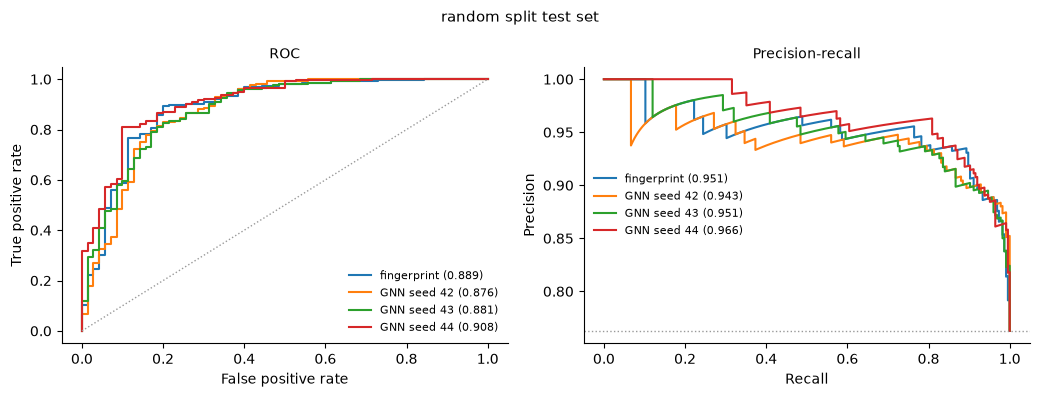

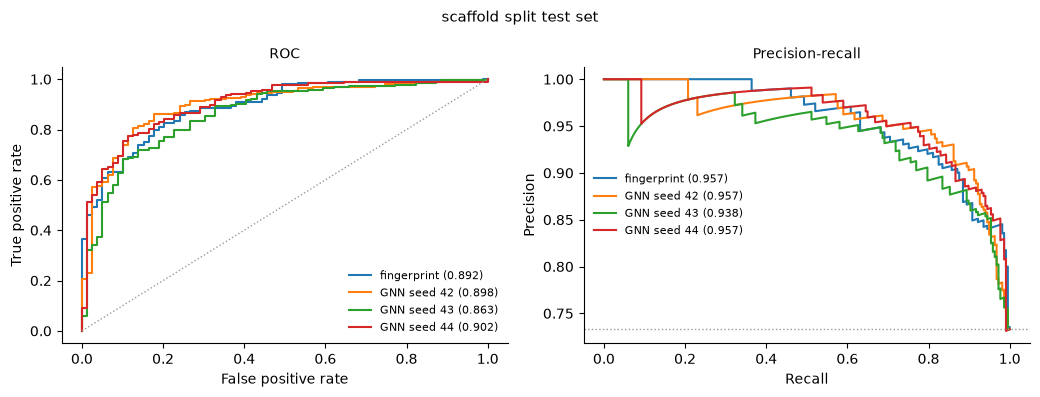

In [32]:
for name in splits:
    curves = {"fingerprint": test_probabilities[("fingerprint", name, SEED)]}
    for seed in SEEDS:
        curves[f"GNN seed {seed}"] = test_probabilities[("GNN", name, seed)]

    plot_roc_pr(curves, title=f"{name} split test set")

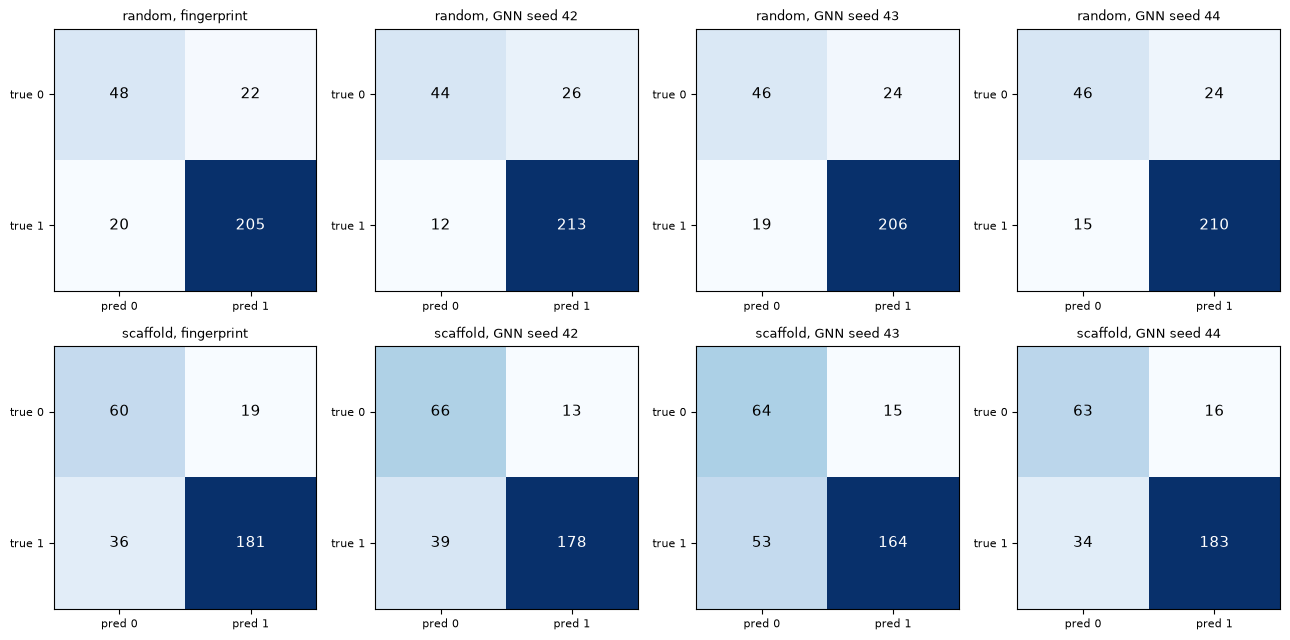

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))

for row, name in enumerate(splits):
    entries = [("fingerprint", SEED)] + [("GNN", seed) for seed in SEEDS]

    for column, (model, seed) in enumerate(entries):
        y_true, probabilities = test_probabilities[(model, name, seed)]
        match = test_results[
            (test_results["model"] == model)
            & (test_results["split"] == name)
            & (test_results["seed"] == seed)
        ]
        threshold = float(match["threshold"].iloc[0])

        label = f"{name}, {model}" + (f" seed {seed}" if model == "GNN" else "")
        plot_confusion_matrix(y_true, (probabilities >= threshold).astype(int), ax=axes[row, column], title=label)

plt.tight_layout()
plt.show()

Provide one comparison table containing model, split, threshold and all required metrics. For repeated GNN runs, include mean and standard deviation.

In [34]:
comparison = comparison_table(test_results)

print(comparison.to_string(index=False))

      model    split  runs       threshold         roc_auc          pr_auc        accuracy     sensitivity     specificity              f1
fingerprint   random     1          0.6802          0.8888          0.9513          0.8576          0.9111          0.6857          0.9071
        GNN   random     3 0.5293 ± 0.0580 0.8884 ± 0.0172 0.9532 ± 0.0115 0.8644 ± 0.0090 0.9319 ± 0.0156 0.6476 ± 0.0165 0.9129 ± 0.0066
fingerprint scaffold     1          0.7841          0.8915          0.9573          0.8142          0.8341          0.7595          0.8681
        GNN scaffold     3 0.9148 ± 0.0282 0.8877 ± 0.0212 0.9509 ± 0.0110 0.8086 ± 0.0333 0.8065 ± 0.0454 0.8143 ± 0.0193 0.8602 ± 0.0279


Compare the baseline with the GNN and random with scaffold evaluation. Explain what the evidence supports; do not assume that a GNN must outperform a fingerprint model or that benchmark performance proves biological usefulness.

Baseline against GNN. The two models are indistinguishable on ranking. Test ROC-AUC is 0.8888 for the fingerprint baseline against 0.8884 ± 0.0172 for the GNN on the random split, and 0.8915 against 0.8877 ± 0.0212 on the scaffold split. The baseline sits inside one standard deviation of the GNN's three seeds both times, so the evidence does not support the GNN being the better model here: a 67,268-parameter message-passing network reading the full molecular graph does no better than logistic regression on hashed substructure counts. The GNN does move the operating point, with higher sensitivity and lower specificity than the baseline on the random split (0.9319 against 0.9111, and 0.6476 against 0.6857) and the reverse on the scaffold split, but that reflects where each validation-selected threshold landed rather than a difference in how well the molecules are ordered.

Random against scaffold. The two strategies separate on validation but not on test ROC-AUC. The GNN's validation ROC-AUC fell from 0.9037 to 0.8786 when the split changed, yet its test ROC-AUC is 0.8884 and 0.8877, effectively equal. What changes on test are the threshold-dependent metrics: accuracy falls from 0.8644 to 0.8086 and F1 from 0.9129 to 0.8602, while specificity rises from 0.6476 to 0.8143. Part of that follows from the subsets themselves, since the scaffold test set is 73.3% positive against 76.3% for the random one, and part from the much higher thresholds validation selected under the scaffold split (0.9148 against 0.5293). On this evidence the scaffold split alters the balance of errors more than it reduces ranking quality. Both test subsets hold fewer than 300 molecules, so differences of a few thousandths in ROC-AUC should not be read as real.

What this does not establish. Neither model has been shown to be biologically useful. The labels are curated literature annotations rather than measurements on new compounds, the cleaned dataset is 1965 molecules, and nothing here has been checked against an external experiment. A PR-AUC near 0.95 looks strong until you note that 76% of the data is positive, so precision starts from that floor rather than from zero. The weakest number in the table is specificity, averaging 0.65 on the random split and 0.81 on the scaffold split, and a false positive here means calling a non-penetrating compound penetrant, which is the error that would matter most in any real screening use.

### Part G. Error, similarity and limitations analysis

On the scaffold-split test set, display at least two false-positive and two false-negative molecules with their labels and predicted probabilities.

In [35]:
ERROR_MODEL, ERROR_SPLIT, ERROR_SEED = "GNN", "scaffold", SEED

y_test, p_test = test_probabilities[(ERROR_MODEL, ERROR_SPLIT, ERROR_SEED)]
test_positions = scaffold_indices[2]

row = test_results[
    (test_results["model"] == ERROR_MODEL)
    & (test_results["split"] == ERROR_SPLIT)
    & (test_results["seed"] == ERROR_SEED)
]
threshold = float(row["threshold"].iloc[0])

errors = pd.DataFrame({
    "position": test_positions,
    "smiles": clean_table["smiles"].to_numpy()[test_positions],
    "label": y_test.astype(int),
    "probability": p_test.round(4),
    "prediction": (p_test >= threshold).astype(int),
})

false_positives = errors[(errors["label"] == 0) & (errors["prediction"] == 1)].sort_values("probability", ascending=False)
false_negatives = errors[(errors["label"] == 1) & (errors["prediction"] == 0)].sort_values("probability")

print("threshold:", threshold)
print("false positives:", len(false_positives), "| false negatives:", len(false_negatives))
print()
print(false_positives.head(2).to_string(index=False))
print()
print(false_negatives.head(2).to_string(index=False))

threshold: 0.9038
false positives: 13 | false negatives: 39

 position                                    smiles  label  probability  prediction
      342 Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4      0       0.9990           1
      252                       NC(N)=NCCN1CCCCCCC1      0       0.9985           1

 position                         smiles  label  probability  prediction
     1381                CC1OC(C)OC(O1)C      1       0.0015           0
     1210 [C@@H]1([P](O)(O)=O)[C@H](C)O1      1       0.0154           0


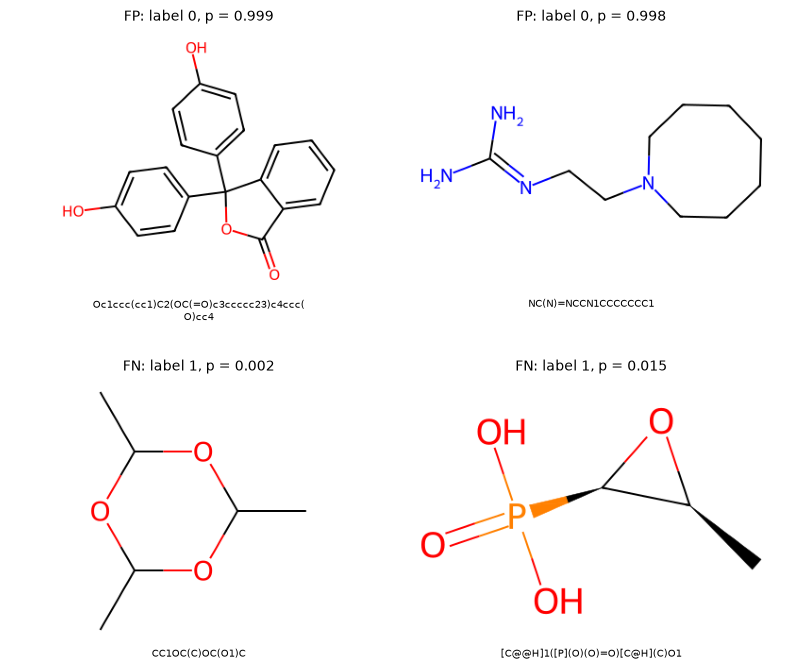

In [36]:
selected_errors = pd.concat([false_positives.head(2), false_negatives.head(2)])

titles = [
    f"{'FP' if row.label == 0 else 'FN'}: label {row.label}, p = {row.probability:.3f}"
    for row in selected_errors.itertuples()
]

draw_molecules(selected_errors["smiles"].tolist(), selected_errors["label"].tolist(), titles=titles, columns=2)

For each selected error, use Morgan-fingerprint Tanimoto similarity to find the most similar training molecule. Display the pair and report similarity, labels and predictions. Discuss whether similarity helps explain the error or confidence.

In [37]:
train_positions = scaffold_indices[0]
train_fingerprints = fingerprints[train_positions]

neighbours = [nearest_training_molecule(fingerprints[row.position], train_fingerprints) for row in selected_errors.itertuples()]

neighbour_positions = np.array([train_positions[i] for i, _ in neighbours])

neighbour_loader = DataLoader(clean_graphs[neighbour_positions], batch_size=BATCH_SIZE, shuffle=False)
_, neighbour_probabilities = predict(gnn_runs[(ERROR_SPLIT, ERROR_SEED)]["model"], neighbour_loader, DEVICE)

similarity_table = pd.DataFrame({
    "error": ["FP" if label == 0 else "FN" for label in selected_errors["label"]],
    "test_label": selected_errors["label"].to_numpy(),
    "test_probability": selected_errors["probability"].to_numpy(),
    "neighbour_label": labels[neighbour_positions].astype(int),
    "neighbour_probability": neighbour_probabilities.round(4),
    "similarity": [round(similarity, 3) for _, similarity in neighbours],
    "test_smiles": selected_errors["smiles"].to_numpy(),
    "neighbour_smiles": clean_table["smiles"].to_numpy()[neighbour_positions],
})

print(similarity_table.drop(columns=["test_smiles", "neighbour_smiles"]).to_string(index=False))

error  test_label  test_probability  neighbour_label  neighbour_probability  similarity
   FP           0            0.9990                1                 0.8370       0.231
   FP           0            0.9985                1                 0.9957       0.273
   FN           1            0.0015                1                 0.9988       0.133
   FN           1            0.0154                1                 0.9758       0.172


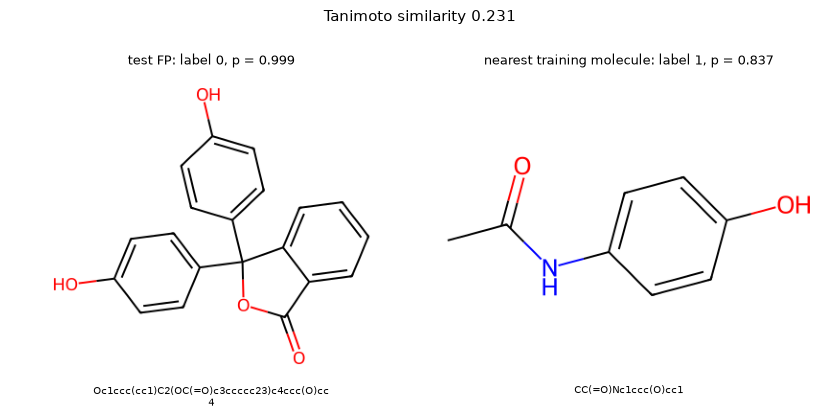

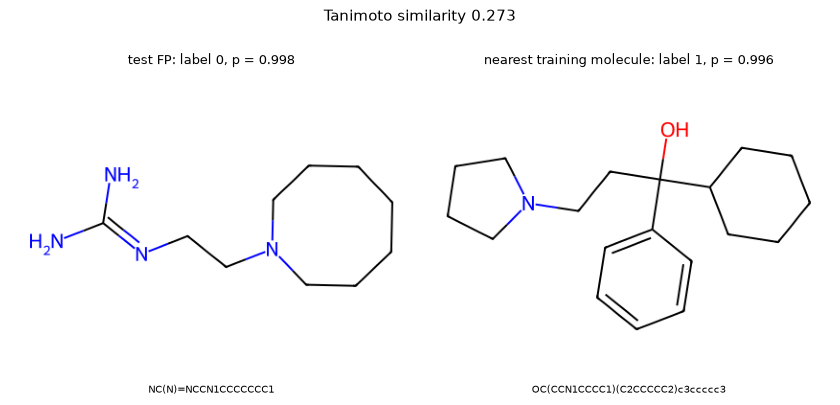

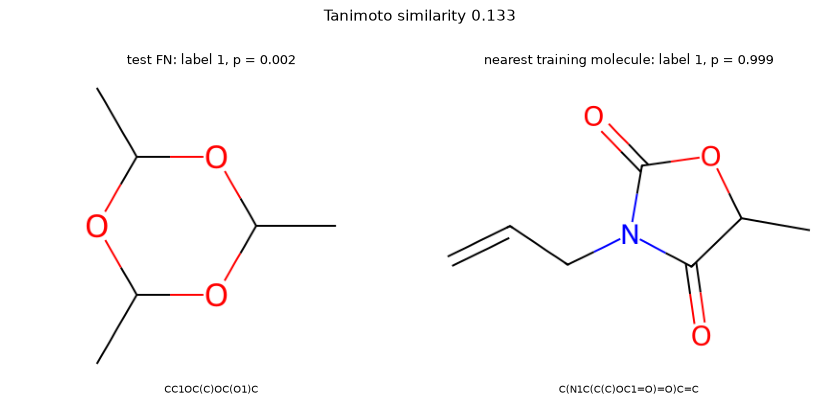

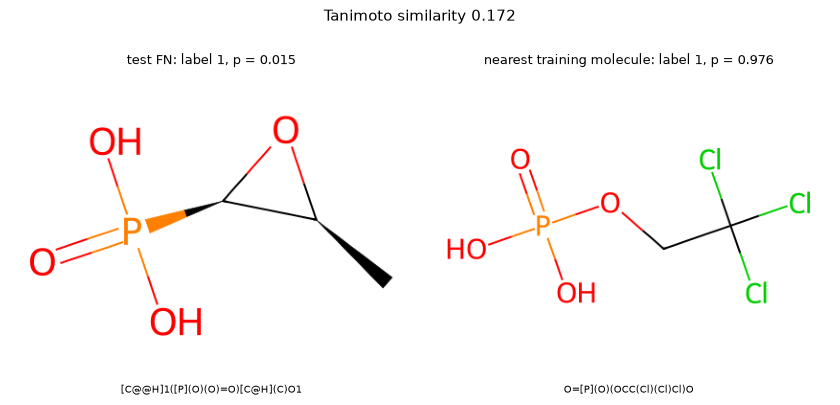

In [38]:
for entry in similarity_table.itertuples():
    plot_similar_pair(entry.test_smiles, entry.neighbour_smiles, {
        "query": f"test {entry.error}: label {entry.test_label}, p = {entry.test_probability:.3f}",
        "neighbour": f"nearest training molecule: label {entry.neighbour_label}, p = {entry.neighbour_probability:.3f}",
        "similarity": entry.similarity,
    })

Every one of the four errors is far from anything in training: Tanimoto similarity to the nearest training molecule is 0.231 and 0.273 for the false positives and 0.133 and 0.172 for the false negatives, against 1.0 for an identical fingerprint. The closest match to phenolphthalein is paracetamol, sharing only a phenol group. This is the scaffold split working as intended, since no test molecule shares a scaffold with training.

Similarity does not explain these errors or the confidence behind them. All four nearest neighbours carry label 1 and the model predicts all four positive, from 0.837 to 0.996. If predictions were being inherited from the nearest training molecule, both false negatives would have come out positive, yet they score 0.0015 and 0.0154. The confident wrong answers cannot be traced to a nearby training example, and with no close analogue available, a high-confidence error is better read as a warning that the probabilities are not calibrated for chemistry outside the training distribution.

State at least three limitations, including label uncertainty, dataset size and the absence of external experimental validation. Explain why the model must not be interpreted as establishing causality or clinical suitability.

1. Label uncertainty. The labels are literature annotations collected by Martins et al. (2012) from studies using different assays, not measurements made under one protocol. The dataset disagrees with itself: 10 canonical structures appear twice with opposite labels, aspirin among them, and those 20 records were removed in Part A. Molecules that disagree are visible; ones that are simply wrong are not.

2. Dataset size. 1965 molecules survive cleaning and each test subset holds fewer than 300. The scaffold test set contains 79 negatives, so one molecule moves specificity by more than a percentage point. Differences of a few thousandths in ROC-AUC cannot be resolved at this size, which is why the baseline and the GNN could not be separated in Part F.

3. No external experimental validation. Nothing here has been checked against a new measurement. Every number comes from held-out parts of one curated benchmark, so the results describe performance on this dataset, not on compounds a laboratory would supply next.

The model is a correlation between substructure patterns and a recorded label. It was fitted, not intervened upon: nothing was altered in a molecule to observe the effect on penetration, so no causal claim follows. Penetration also depends on active transport and efflux, which a 2D graph does not encode, so the model cannot be said to capture the mechanism. It is not clinically suitable either. Specificity averages 0.65 on the random split and 0.81 on the scaffold split, the most confident errors in G.1 are wrong at p = 0.999, and G.2 shows the probabilities are not calibrated for chemistry unlike the training set. At most this ranks compounds for a later experiment.

